In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("india_housing_prices.csv")

In [3]:
df.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [4]:
df.shape

(250000, 23)

In [5]:
df.isnull().sum()

ID                                0
State                             0
City                              0
Locality                          0
Property_Type                     0
BHK                               0
Size_in_SqFt                      0
Price_in_Lakhs                    0
Price_per_SqFt                    0
Year_Built                        0
Furnished_Status                  0
Floor_No                          0
Total_Floors                      0
Age_of_Property                   0
Nearby_Schools                    0
Nearby_Hospitals                  0
Public_Transport_Accessibility    0
Parking_Space                     0
Security                          0
Amenities                         0
Facing                            0
Owner_Type                        0
Availability_Status               0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  str    
 2   City                            250000 non-null  str    
 3   Locality                        250000 non-null  str    
 4   Property_Type                   250000 non-null  str    
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  str    
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors               

In [8]:
df.describe()

,ID,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals
count,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000,250000.000000
mean,125000.500000,2.999396,2749.813216,254.586854,0.130597,2006.520012,14.966800,15.503004,18.479988,5.499860,5.498016
std,72168.927986,1.415521,1300.606954,141.349921,0.130747,9.808575,8.948047,8.671618,9.808575,2.878639,2.871860
min,1.000000,1.000000,500.000000,10.000000,0.000000,1990.000000,0.000000,1.000000,2.000000,1.000000,1.000000
25%,62500.750000,2.000000,1623.000000,132.550000,0.050000,1998.000000,7.000000,8.000000,10.000000,3.000000,3.000000
50%,125000.500000,3.000000,2747.000000,253.870000,0.090000,2007.000000,15.000000,15.000000,18.000000,5.000000,5.000000
75%,187500.250000,4.000000,3874.000000,376.880000,0.160000,2015.000000,23.000000,23.000000,27.000000,8.000000,8.000000
max,250000.000000,5.000000,5000.000000,500.000000,0.990000,2023.000000,30.000000,30.000000,35.000000,10.000000,10.000000


In [9]:
print("Duplicate Property IDs:", df["ID"].duplicated().sum())
print("Unique Property IDs:", df["ID"].nunique())

Duplicate Property IDs: 0
Unique Property IDs: 250000


In [10]:
print("Invalid Prices:", (df["Price_in_Lakhs"] <= 0).sum())
print("Invalid Sizes:", (df["Size_in_SqFt"] <= 0).sum())
print("Invalid BHK:", (df["BHK"] <= 0).sum())
print("Invalid Year Built:", (df["Year_Built"] > 2026).sum())

Invalid Prices: 0
Invalid Sizes: 0
Invalid BHK: 0
Invalid Year Built: 0


In [11]:
df["Calculated_Price_per_SqFt"] = (
    df["Price_in_Lakhs"] * 100000 / df["Size_in_SqFt"]
)

print(df[[
    "Price_in_Lakhs",
    "Size_in_SqFt",
    "Price_per_SqFt",
    "Calculated_Price_per_SqFt"
]].head(10))

   Price_in_Lakhs  Size_in_SqFt  Price_per_SqFt  Calculated_Price_per_SqFt
0          489.76          4740            0.10               10332.489451
1          195.52          2364            0.08                8270.727580
2          183.79          3642            0.05                5046.403075
3          300.29          2741            0.11               10955.490697
4          182.90          4823            0.04                3792.245490
5          135.28          3500            0.04                3865.142857
6          318.12          4826            0.07                6591.794447
7          141.39          4252            0.03                3325.258702
8          189.16          2678            0.07                7063.480209
9          187.42          1393            0.13               13454.414932


In [12]:
df["Price_per_SqFt"] = df["Calculated_Price_per_SqFt"]

df.drop(columns=["Calculated_Price_per_SqFt"], inplace=True)

print(df[["Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt"]].head())

   Price_in_Lakhs  Size_in_SqFt  Price_per_SqFt
0          489.76          4740    10332.489451
1          195.52          2364     8270.727580
2          183.79          3642     5046.403075
3          300.29          2741    10955.490697
4          182.90          4823     3792.245490


In [13]:
df.to_csv("cleaned_housing_prices.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", df.shape)

Cleaned dataset saved successfully!
Dataset shape: (250000, 23)


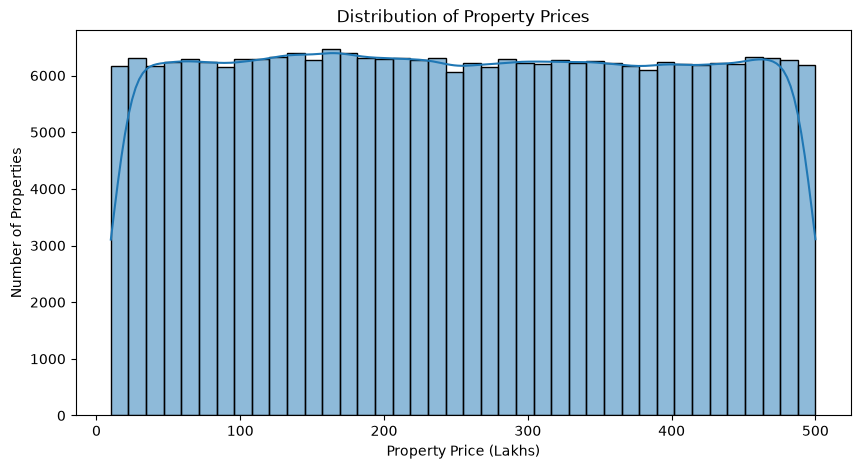

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Price_in_Lakhs"], bins=40, kde=True)

plt.title("Distribution of Property Prices")
plt.xlabel("Property Price (Lakhs)")
plt.ylabel("Number of Properties")

plt.show()

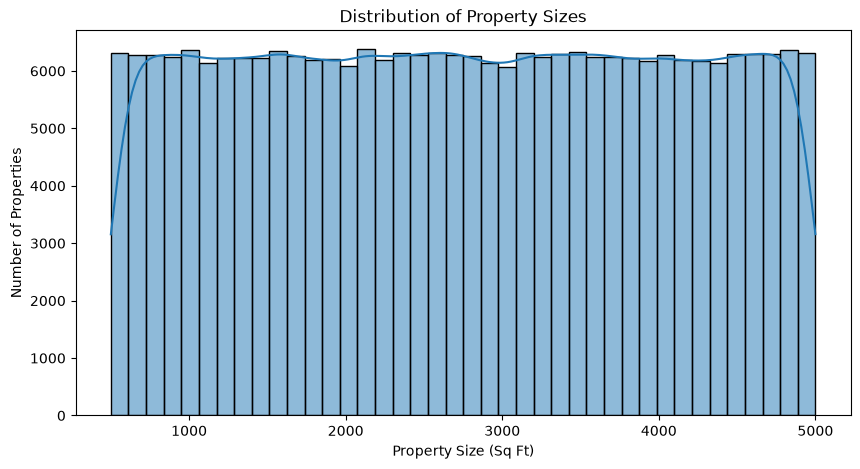

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Size_in_SqFt"], bins=40, kde=True)

plt.title("Distribution of Property Sizes")
plt.xlabel("Property Size (Sq Ft)")
plt.ylabel("Number of Properties")

plt.show()

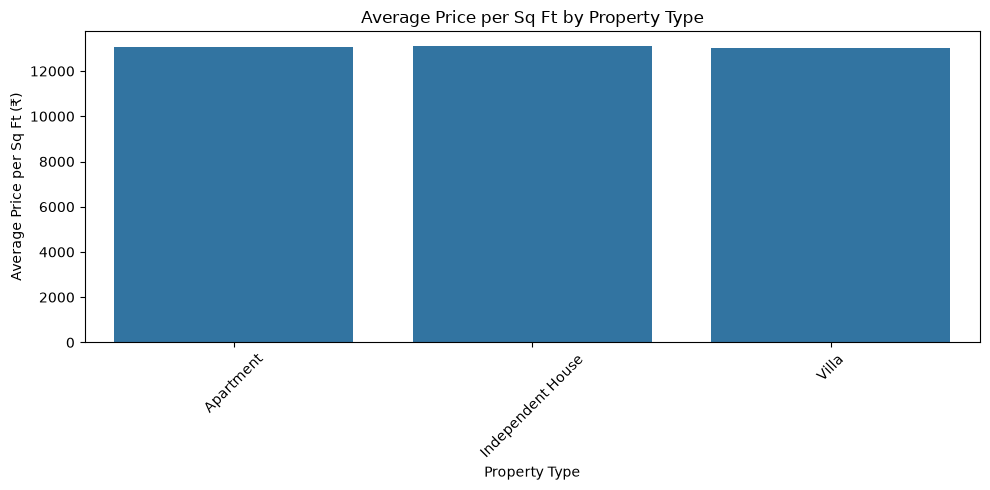

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Property_Type",
    y="Price_per_SqFt",
    estimator="mean",
    errorbar=None
)

plt.title("Average Price per Sq Ft by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Average Price per Sq Ft (₹)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

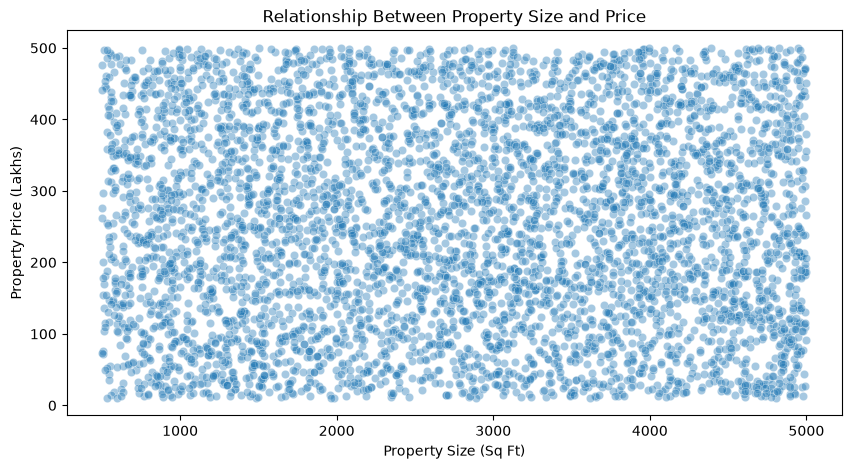

Correlation: -0.0025285467925389013


In [17]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df.sample(n=5000, random_state=42),
    x="Size_in_SqFt",
    y="Price_in_Lakhs",
    alpha=0.4
)

plt.title("Relationship Between Property Size and Price")
plt.xlabel("Property Size (Sq Ft)")
plt.ylabel("Property Price (Lakhs)")

plt.show()

print("Correlation:",
      df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]))

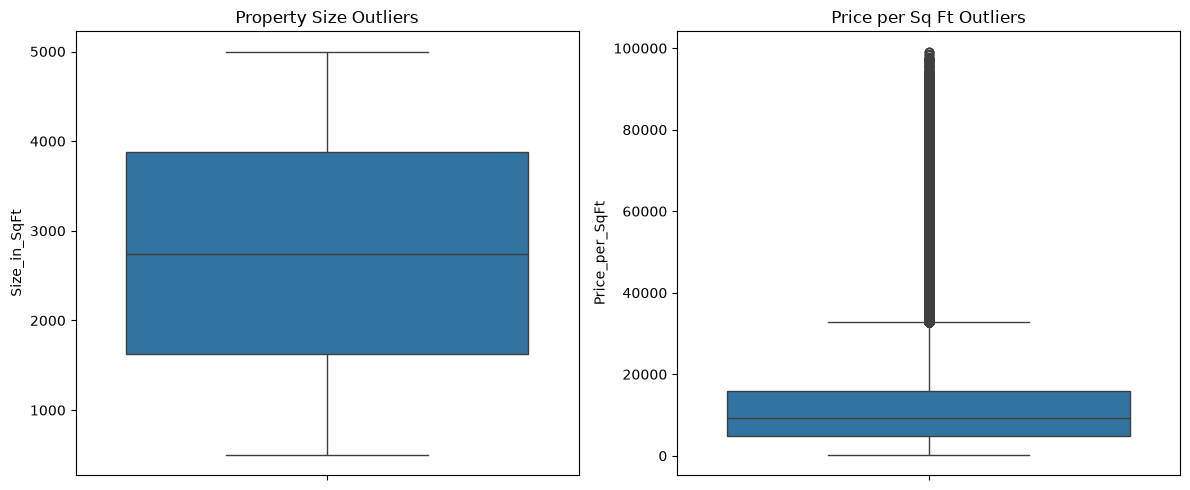

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Size_in_SqFt"], ax=axes[0])
axes[0].set_title("Property Size Outliers")

sns.boxplot(y=df["Price_per_SqFt"], ax=axes[1])
axes[1].set_title("Price per Sq Ft Outliers")

plt.tight_layout()
plt.show()

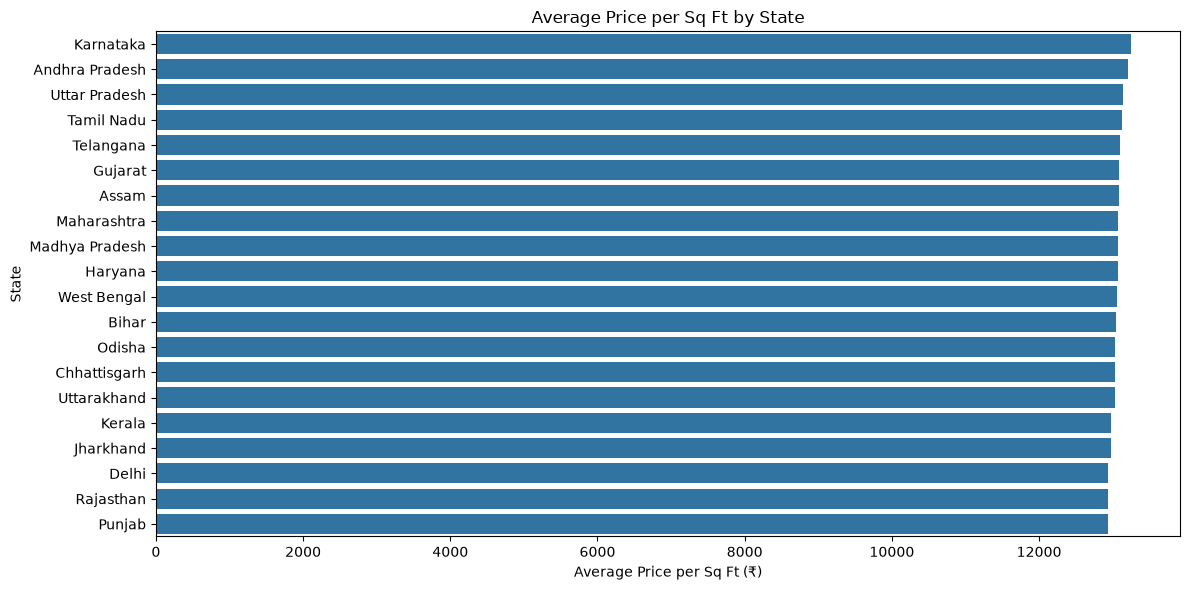

In [19]:
state_prices = (
    df.groupby("State")["Price_per_SqFt"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=state_prices.values,
    y=state_prices.index
)

plt.title("Average Price per Sq Ft by State")
plt.xlabel("Average Price per Sq Ft (₹)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

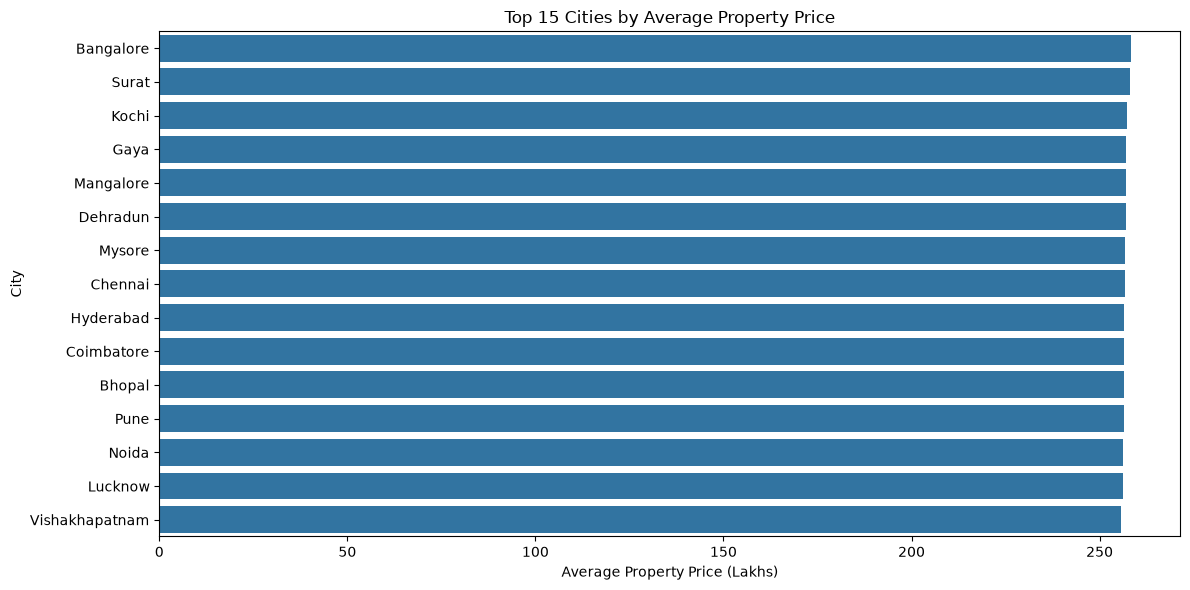

In [20]:
city_prices = (
    df.groupby("City")["Price_in_Lakhs"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=city_prices.values,
    y=city_prices.index
)

plt.title("Top 15 Cities by Average Property Price")
plt.xlabel("Average Property Price (Lakhs)")
plt.ylabel("City")

plt.tight_layout()
plt.show()

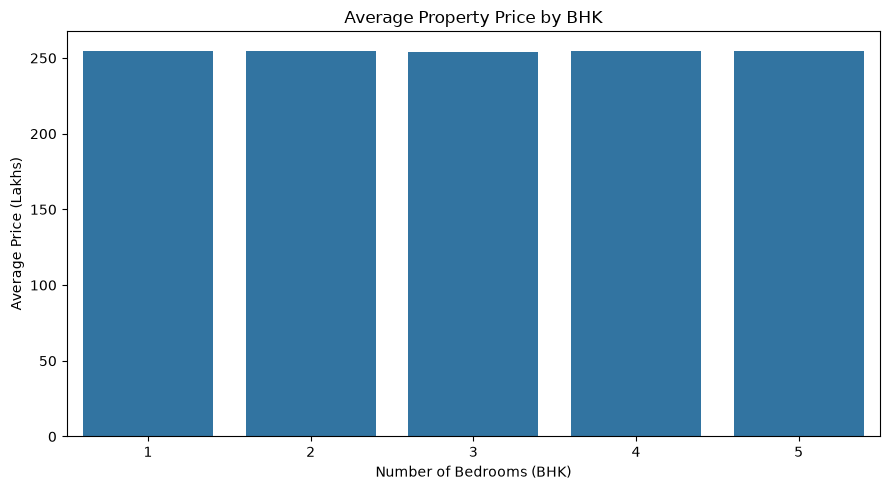

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="BHK",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by BHK")
plt.xlabel("Number of Bedrooms (BHK)")
plt.ylabel("Average Price (Lakhs)")

plt.tight_layout()
plt.show()

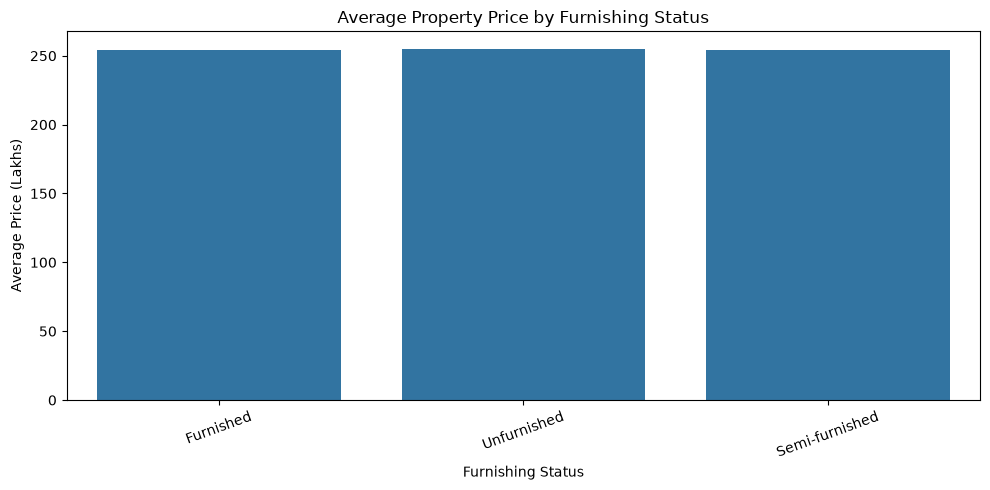

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Furnished_Status",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Average Price (Lakhs)")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

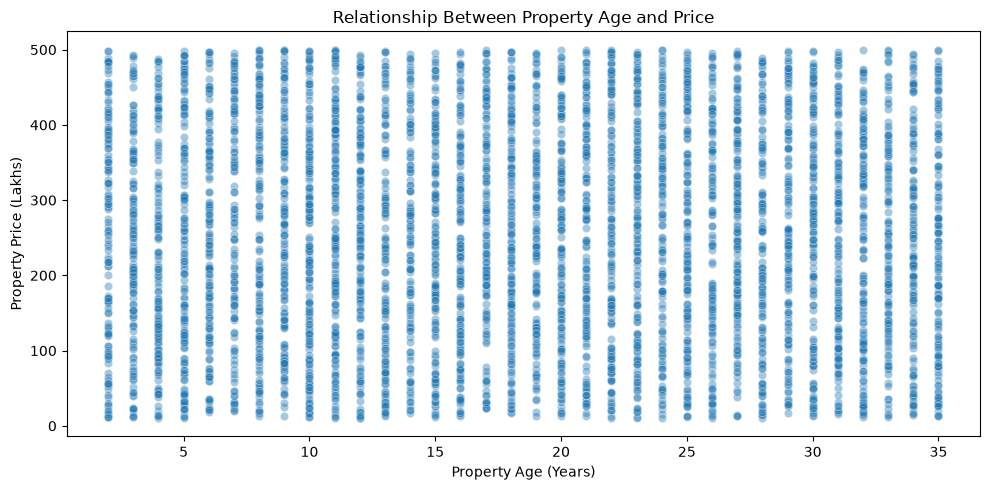

Correlation: -0.002713743573983126


In [23]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df.sample(n=5000, random_state=42),
    x="Age_of_Property",
    y="Price_in_Lakhs",
    alpha=0.4
)

plt.title("Relationship Between Property Age and Price")
plt.xlabel("Property Age (Years)")
plt.ylabel("Property Price (Lakhs)")

plt.tight_layout()
plt.show()

print("Correlation:",
      df["Age_of_Property"].corr(df["Price_in_Lakhs"]))

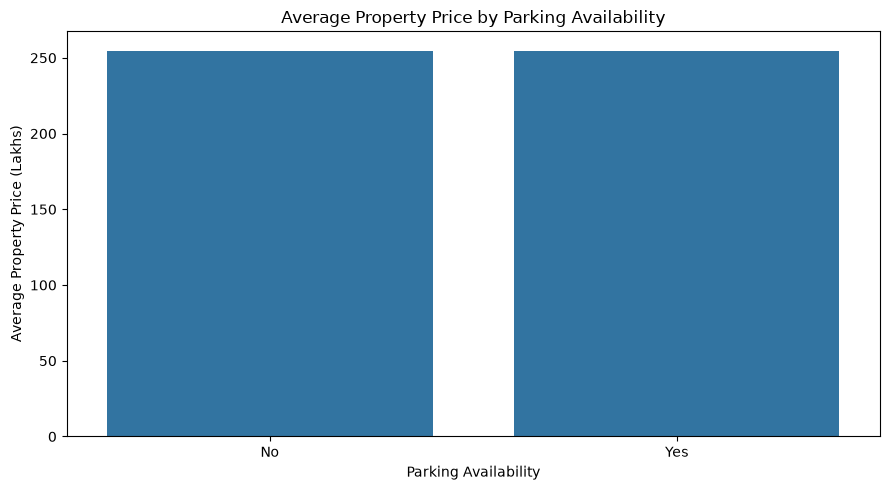

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Parking_Space",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Parking Availability")
plt.xlabel("Parking Availability")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

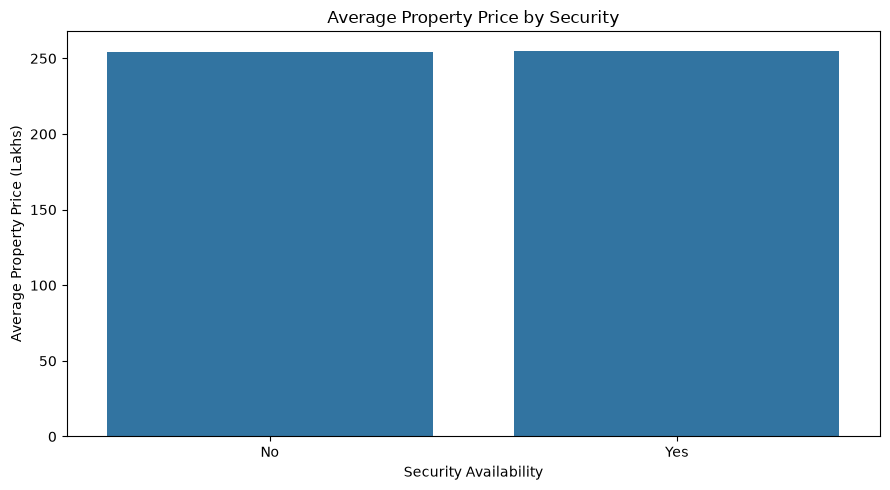

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Security",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Security")
plt.xlabel("Security Availability")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

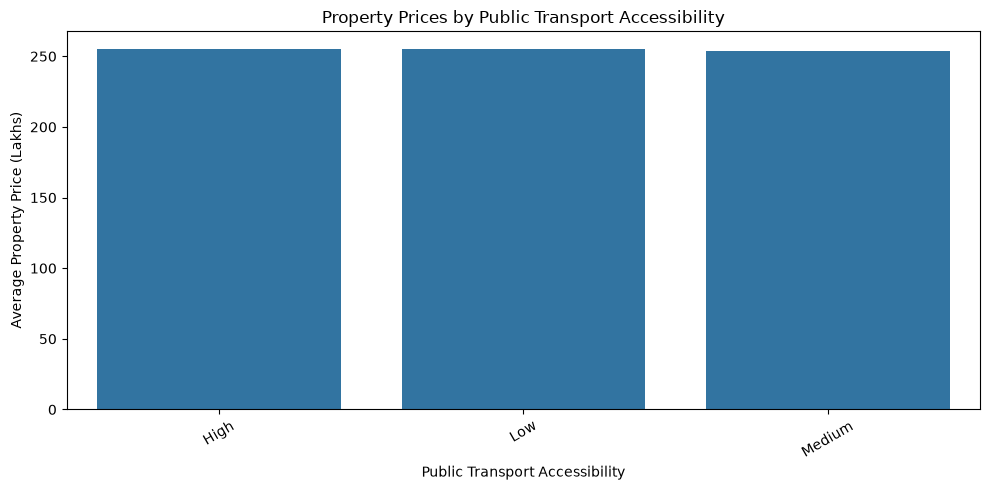

In [26]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Public_Transport_Accessibility",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Property Prices by Public Transport Accessibility")
plt.xlabel("Public Transport Accessibility")
plt.ylabel("Average Property Price (Lakhs)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

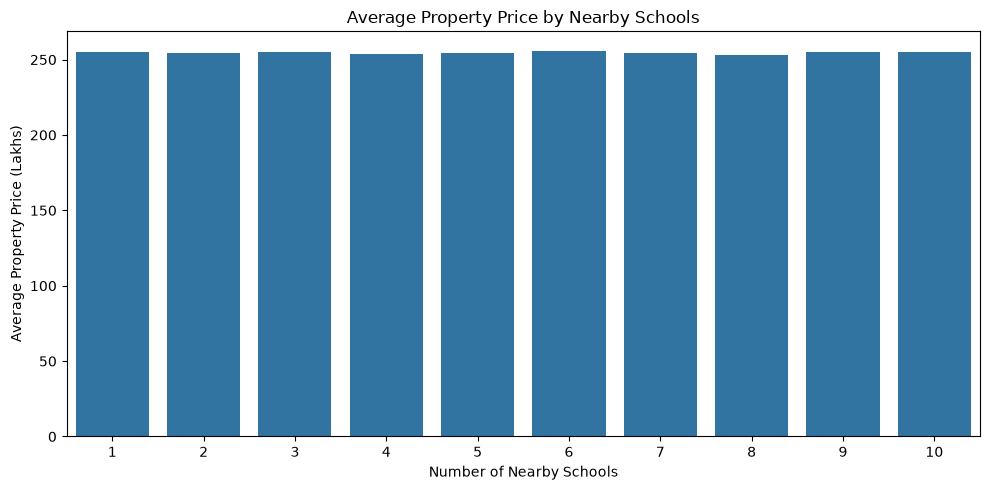

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Nearby_Schools",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Nearby Schools")
plt.xlabel("Number of Nearby Schools")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

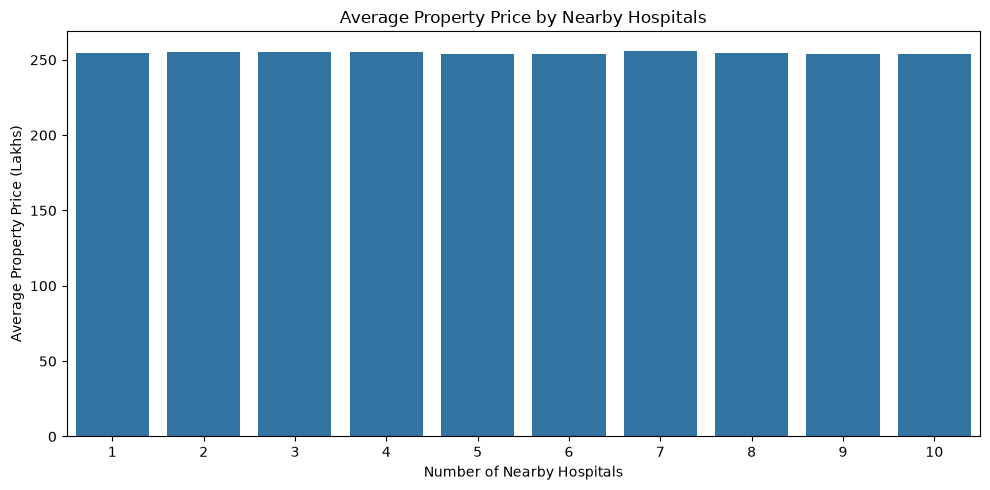

In [28]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Nearby_Hospitals",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Nearby Hospitals")
plt.xlabel("Number of Nearby Hospitals")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

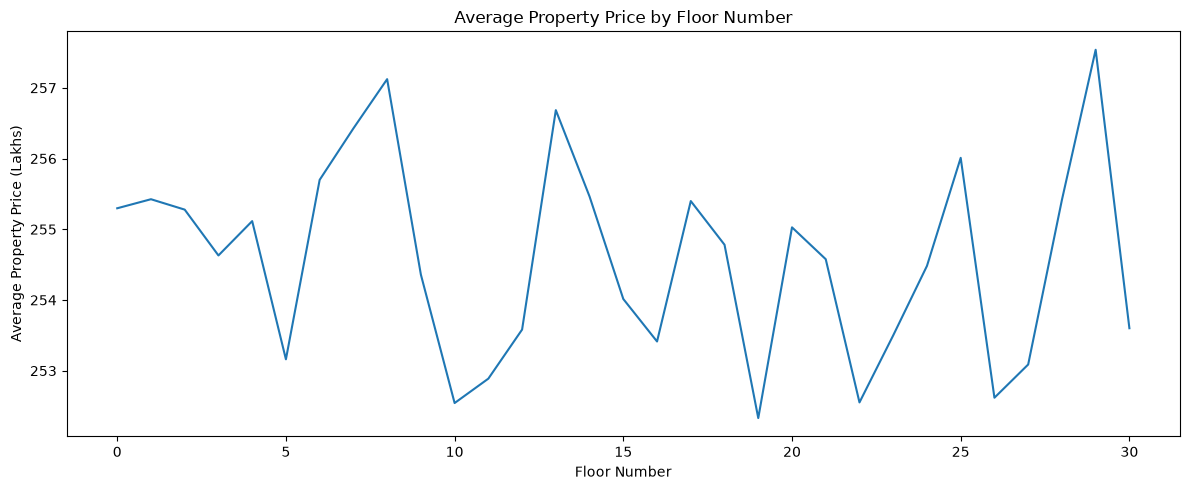

In [29]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df,
    x="Floor_No",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Floor Number")
plt.xlabel("Floor Number")
plt.ylabel("Average Property Price (Lakhs)")

plt.tight_layout()
plt.show()

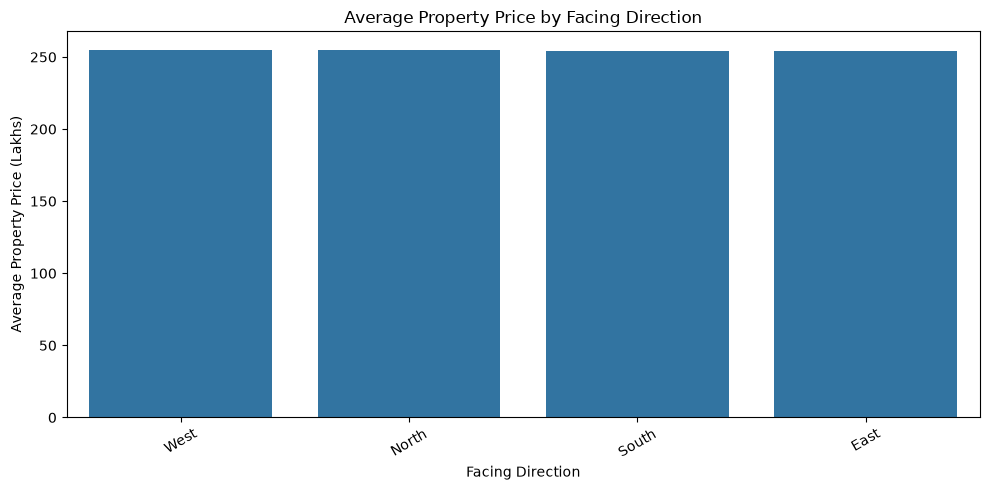

In [30]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Facing",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Facing Direction")
plt.xlabel("Facing Direction")
plt.ylabel("Average Property Price (Lakhs)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

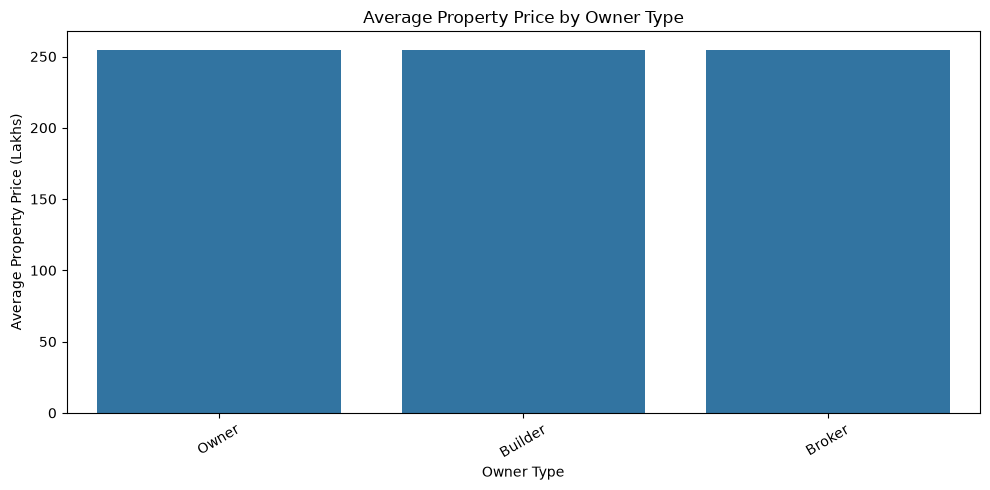

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Owner_Type",
    y="Price_in_Lakhs",
    estimator="mean",
    errorbar=None
)

plt.title("Average Property Price by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Average Property Price (Lakhs)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

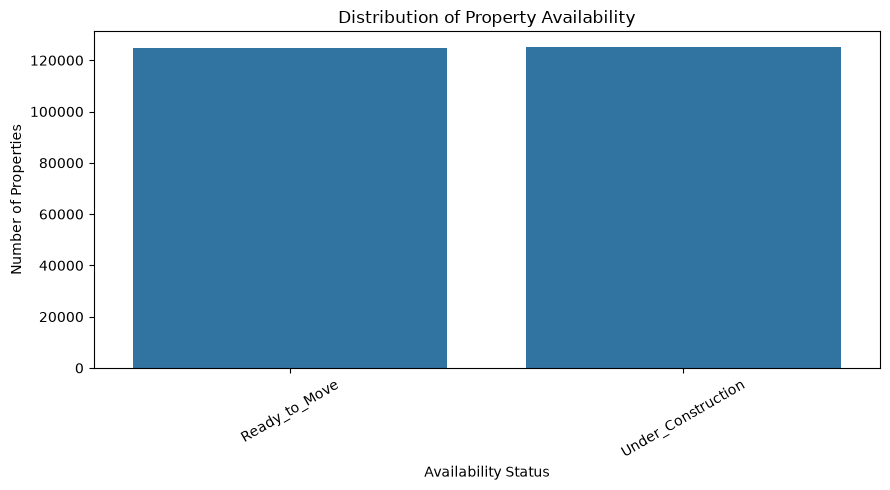

Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64


In [32]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Availability_Status"
)

plt.title("Distribution of Property Availability")
plt.xlabel("Availability Status")
plt.ylabel("Number of Properties")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

print(df["Availability_Status"].value_counts())

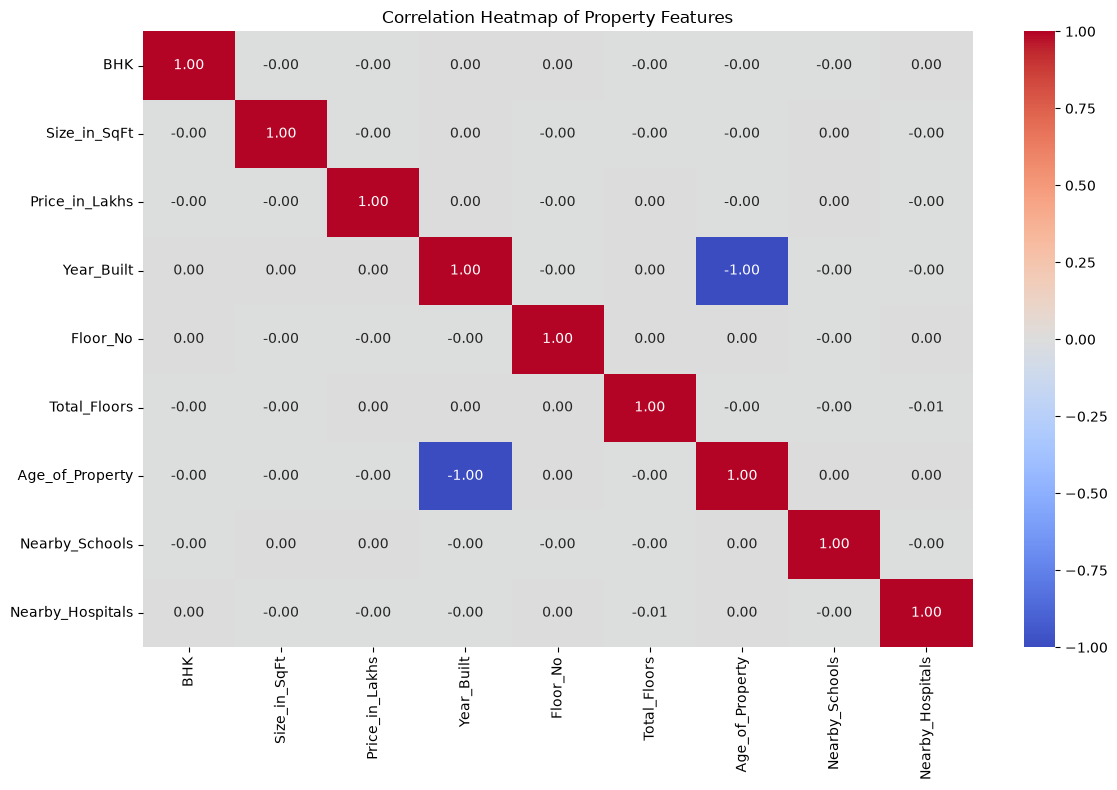

In [33]:
numeric_df = df.select_dtypes(include=["number"]).drop(
    columns=["ID", "Price_per_SqFt"],
    errors="ignore"
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Property Features")
plt.tight_layout()
plt.show()

In [34]:
print("REAL ESTATE DATA ANALYSIS SUMMARY")
print("--------------------------------")

print("Total Properties:", len(df))

print("Average Price (Lakhs):",
      round(df["Price_in_Lakhs"].mean(), 2))

print("Average Size (Sq Ft):",
      round(df["Size_in_SqFt"].mean(), 2))

print("Most Common Property Type:",
      df["Property_Type"].mode()[0])

print("Most Common BHK:",
      df["BHK"].mode()[0])

print("Highest Average Price City:",
      df.groupby("City")["Price_in_Lakhs"].mean().idxmax())

print("Highest Average Price State:",
      df.groupby("State")["Price_in_Lakhs"].mean().idxmax())

print("Size-Price Correlation:",
      round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 4))

REAL ESTATE DATA ANALYSIS SUMMARY
--------------------------------
Total Properties: 250000
Average Price (Lakhs): 254.59
Average Size (Sq Ft): 2749.81
Most Common Property Type: Villa
Most Common BHK: 1
Highest Average Price City: Bangalore
Highest Average Price State: Karnataka
Size-Price Correlation: -0.0025


In [35]:
summary = df.describe(include="all").T

summary.to_csv("real_estate_summary.csv")

print("Summary saved successfully!")

Summary saved successfully!


City        Locality    
Mysore      Locality_444    34.5
            Locality_70     34.0
Hyderabad   Locality_356    34.0
Mumbai      Locality_349    34.0
Bangalore   Locality_331    33.0
Nagpur      Locality_426    33.0
Kochi       Locality_183    33.0
Mangalore   Locality_344    33.0
Jaipur      Locality_249    33.0
Jamshedpur  Locality_179    33.0
Mangalore   Locality_481    33.0
Bangalore   Locality_57     33.0
            Locality_353    32.5
Bilaspur    Locality_47     32.5
Dwarka      Locality_414    32.5
Name: Age_of_Property, dtype: float64


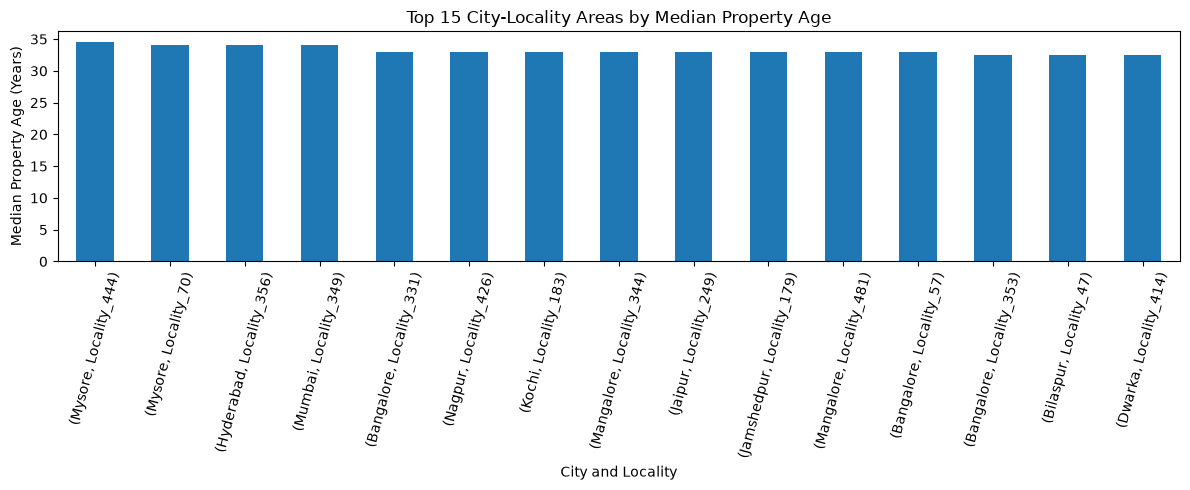

In [36]:
locality_age = (
    df.groupby(["City", "Locality"])["Age_of_Property"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

print(locality_age)

locality_age.plot(kind="bar", figsize=(12, 5))

plt.title("Top 15 City-Locality Areas by Median Property Age")
plt.xlabel("City and Locality")
plt.ylabel("Median Property Age (Years)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

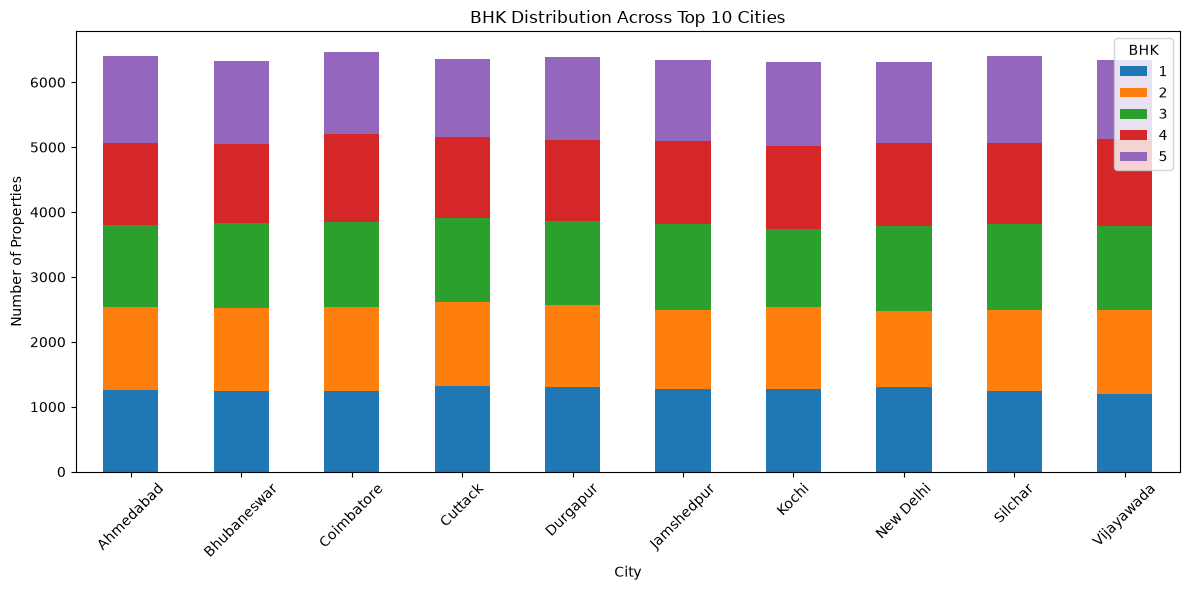

In [37]:
top_cities = df["City"].value_counts().head(10).index

bhk_city = pd.crosstab(
    df.loc[df["City"].isin(top_cities), "City"],
    df.loc[df["City"].isin(top_cities), "BHK"]
)

bhk_city.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("BHK Distribution Across Top 10 Cities")
plt.xlabel("City")
plt.ylabel("Number of Properties")
plt.legend(title="BHK")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
locality_counts = (
    df.groupby(["City", "Locality"])
    .size()
    .sort_values(ascending=False)
)

print(locality_counts.head(10))
print("Maximum properties:", locality_counts.max())

City        Locality    
Trivandrum  Locality_113    29
Kochi       Locality_140    29
Jamshedpur  Locality_480    28
Coimbatore  Locality_257    28
Trivandrum  Locality_164    27
Ranchi      Locality_236    27
New Delhi   Locality_129    27
Warangal    Locality_449    27
Guwahati    Locality_368    26
Bhopal      Locality_492    26
dtype: int64
Maximum properties: 29


In [40]:
top_localities = (
    df.groupby(["City", "Locality"])
    .agg(
        Average_Price_per_SqFt=("Price_per_SqFt", "mean"),
        Property_Count=("ID", "count")
    )
    .sort_values("Average_Price_per_SqFt", ascending=False)
    .head(5)
)

print(top_localities)

                       Average_Price_per_SqFt  Property_Count
City     Locality                                            
Mysore   Locality_387            45324.093695               4
Pune     Locality_316            41424.272125               6
Mumbai   Locality_90             39878.317112               3
Amritsar Locality_444            39733.123480               5
Surat    Locality_138            37722.315751               3


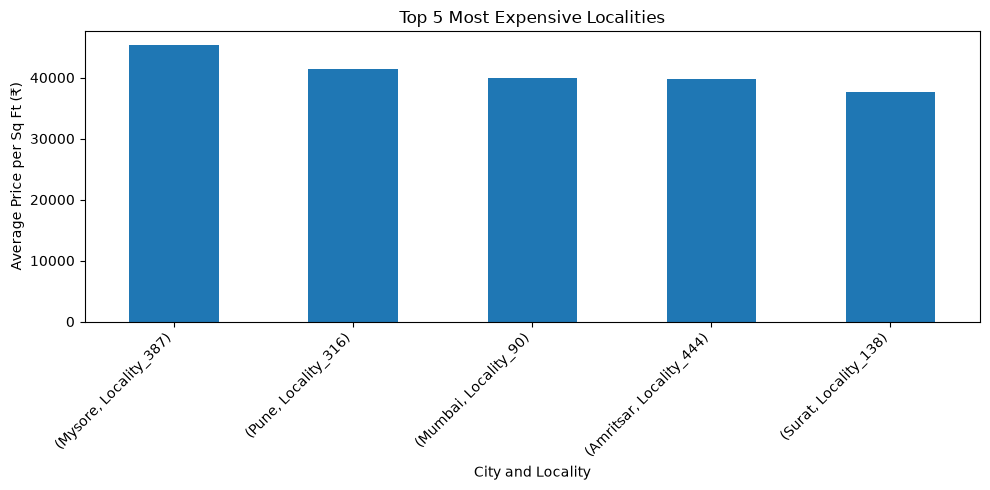

In [41]:
plt.figure(figsize=(10, 5))

top_localities["Average_Price_per_SqFt"].plot(
    kind="bar"
)

plt.title("Top 5 Most Expensive Localities")
plt.xlabel("City and Locality")
plt.ylabel("Average Price per Sq Ft (₹)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [42]:
ml_df = df.copy()

print("Dataset Shape:", ml_df.shape)
print("Total Columns:", ml_df.columns.tolist())

Dataset Shape: (250000, 23)
Total Columns: ['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


In [43]:
ml_df["Property_Age"] = ml_df["Age_of_Property"]

ml_df["Amenities_Count"] = (
    ml_df["Amenities"]
    .fillna("")
    .astype(str)
    .apply(lambda x: len([a for a in x.split(",") if a.strip()]))
)

ml_df["Floor_Ratio"] = (
    ml_df["Floor_No"] / ml_df["Total_Floors"]
)

print(ml_df[[
    "Property_Age",
    "Amenities_Count",
    "Floor_Ratio"
]].head())

   Property_Age  Amenities_Count  Floor_Ratio
0            35                5    22.000000
1            17                5     1.050000
2            28                4     0.703704
3            34                5     0.807692
4            23                5     1.500000


In [44]:
print(ml_df[[
    "Property_Age",
    "Amenities_Count",
    "Floor_Ratio"
]].describe())

print("\nSample amenities:")
print(ml_df["Amenities"].head(10).to_string())

print("\nInvalid floor ratios:",
      ((ml_df["Floor_Ratio"] < 0) |
       (ml_df["Floor_Ratio"] > 1)).sum())

        Property_Age  Amenities_Count    Floor_Ratio
count  250000.000000    250000.000000  250000.000000
mean       18.479988         3.000288       1.995351
std         9.808575         1.414284       3.518869
min         2.000000         1.000000       0.000000
25%        10.000000         2.000000       0.466667
50%        18.000000         3.000000       0.964286
75%        27.000000         4.000000       1.888889
max        35.000000         5.000000      30.000000

Sample amenities:
0    Playground, Gym, Garden, Pool, Clubhouse
1    Playground, Clubhouse, Pool, Gym, Garden
2            Clubhouse, Pool, Playground, Gym
3    Playground, Clubhouse, Gym, Pool, Garden
4    Playground, Garden, Gym, Pool, Clubhouse
5                       Playground, Clubhouse
6               Clubhouse, Garden, Playground
7            Gym, Pool, Clubhouse, Playground
8               Garden, Clubhouse, Playground
9          Clubhouse, Playground, Garden, Gym

Invalid floor ratios: 116304


In [45]:
import numpy as np

features = ["Property_Age", "Amenities_Count", "Floor_Ratio"]

print("Missing values:")
print(ml_df[features].isnull().sum())

print("\nInfinite values:")
print(np.isinf(ml_df[features]).sum())

Missing values:
Property_Age       0
Amenities_Count    0
Floor_Ratio        0
dtype: int64

Infinite values:
Property_Age       0
Amenities_Count    0
Floor_Ratio        0
dtype: int64


In [46]:
print("Properties with zero total floors:",
      (ml_df["Total_Floors"] == 0).sum())

print("Properties with floor above total floors:",
      (ml_df["Floor_No"] > ml_df["Total_Floors"]).sum())

print("Properties with negative floor numbers:",
      (ml_df["Floor_No"] < 0).sum())


Properties with zero total floors: 0
Properties with floor above total floors: 116304
Properties with negative floor numbers: 0


In [47]:
print("Sample amenities:")
print(ml_df["Amenities"].value_counts().head(15))

print("\nAmenities count distribution:")
print(ml_df["Amenities_Count"].value_counts().sort_index())

Sample amenities:
Amenities
Pool                     10218
Clubhouse                10010
Garden                   10006
Gym                       9938
Playground                9934
Pool, Playground          2545
Gym, Pool                 2534
Garden, Clubhouse         2524
Gym, Playground           2524
Playground, Gym           2519
Clubhouse, Playground     2516
Playground, Clubhouse     2506
Garden, Gym               2504
Gym, Garden               2500
Garden, Playground        2498
Name: count, dtype: int64

Amenities count distribution:
Amenities_Count
1    50106
2    49806
3    49862
4    50362
5    49864
Name: count, dtype: int64


In [48]:
invalid_floors = ml_df[
    ml_df["Floor_No"] > ml_df["Total_Floors"]
]

print("Invalid floor records:", len(invalid_floors))

print(invalid_floors[
    ["Floor_No", "Total_Floors"]
].head(10))

Invalid floor records: 116304
    Floor_No  Total_Floors
0         22             1
1         21            20
4          3             2
5         27             1
6         16             5
7         24             4
8         23            16
12         9             1
13        13             4
14        26            18


In [49]:
ml_df["Floor_Ratio"] = np.where(
    ml_df["Floor_No"] <= ml_df["Total_Floors"],
    ml_df["Floor_No"] / ml_df["Total_Floors"],
    np.nan
)

print("Missing Floor_Ratio values:",
      ml_df["Floor_Ratio"].isnull().sum())

Missing Floor_Ratio values: 116304


In [50]:
median_ratio = ml_df["Floor_Ratio"].median()

ml_df["Floor_Ratio"] = ml_df["Floor_Ratio"].fillna(
    median_ratio
)

print("Missing values remaining:",
      ml_df["Floor_Ratio"].isnull().sum())

print(ml_df["Floor_Ratio"].describe())

Missing values remaining: 0
count    250000.000000
mean          0.499937
std           0.225201
min           0.000000
25%           0.466667
50%           0.500000
75%           0.533333
max           1.000000
Name: Floor_Ratio, dtype: float64


In [67]:
features = [
    "BHK",
    "Size_in_SqFt",
    "Property_Age",
    "Amenities_Count",
    "Floor_Ratio"
]

X = ml_df[features]
y = ml_df["Price_in_Lakhs"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (250000, 5)
Target shape: (250000,)


In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (200000, 5)
Testing data: (50000, 5)


In [53]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [54]:
y_pred = model.predict(X_test)

print("Actual Prices:", y_test.head(10).values)
print("Predicted Prices:", y_pred[:10])

Actual Prices: [256.62  86.04 237.86 339.41 124.99  35.17 275.75 374.76 476.35 208.  ]
Predicted Prices: [255.26763204 254.93331186 254.16980945 254.55742053 253.27670898
 254.46145842 254.46015986 255.47321468 255.45996331 254.41575608]


In [55]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE: 122.32
RMSE: 141.19
R2 Score: -0.0


   Actual Price  Predicted Price
0        256.62       255.267632
1         86.04       254.933312
2        237.86       254.169809
3        339.41       254.557421
4        124.99       253.276709
5         35.17       254.461458
6        275.75       254.460160
7        374.76       255.473215
8        476.35       255.459963
9        208.00       254.415756


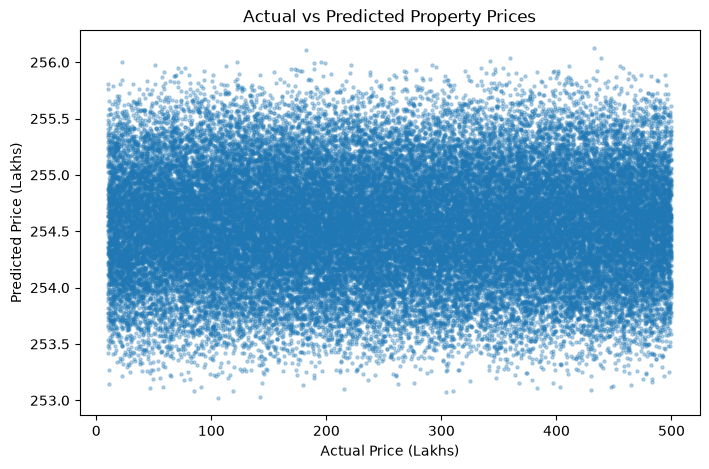

In [56]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=5)
plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Property Prices")
plt.show()

In [57]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [58]:
X_train_sample = X_train.sample(
    n=30000,
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

rf_model.fit(X_train_sample, y_train_sample)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [59]:
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("MAE:", round(rf_mae, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

Random Forest Results
MAE: 122.58
RMSE: 141.65
R2 Score: -0.0065


In [60]:
columns = [
    "BHK",
    "Size_in_SqFt",
    "Property_Age",
    "Amenities_Count",
    "Floor_Ratio",
    "Price_in_Lakhs"
]

correlations = ml_df[columns].corr()

print(correlations["Price_in_Lakhs"])

BHK               -0.000980
Size_in_SqFt      -0.002529
Property_Age      -0.002714
Amenities_Count    0.001029
Floor_Ratio        0.000173
Price_in_Lakhs     1.000000
Name: Price_in_Lakhs, dtype: float64


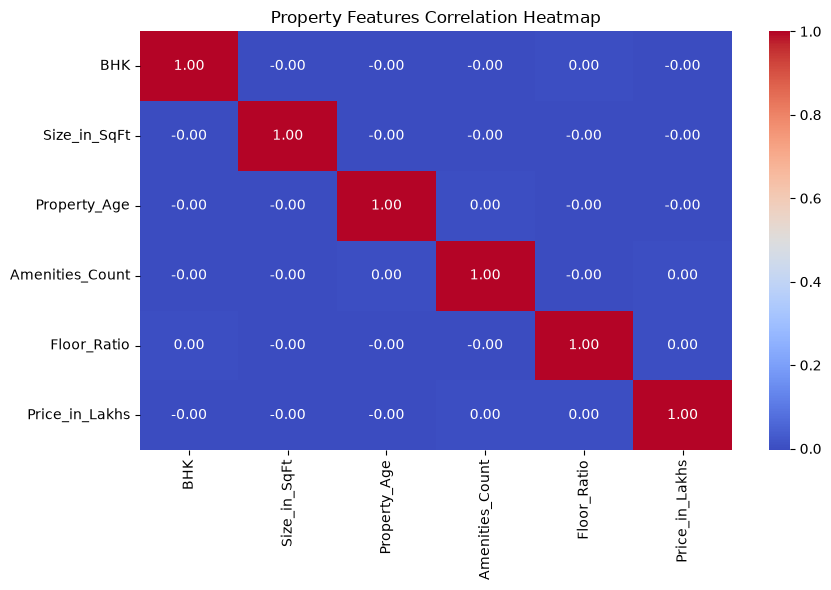

In [61]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlations,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Property Features Correlation Heatmap")
plt.tight_layout()
plt.show()

In [62]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline MAE:",
      round(mean_absolute_error(y_test, baseline_pred), 2))

print("Baseline R2:",
      round(r2_score(y_test, baseline_pred), 4))

Baseline MAE: 122.32
Baseline R2: -0.0


In [63]:

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFeatures used:")
print(X_train.columns.tolist())

print("\nTraining target statistics:")
print(y_train.describe())

print("\nTesting target statistics:")
print(y_test.describe())

print("\nMissing values in training features:")
print(X_train.isnull().sum())


Training data shape: (200000, 5)
Testing data shape: (50000, 5)

Features used:
['BHK', 'Size_in_SqFt', 'Property_Age', 'Amenities_Count', 'Floor_Ratio']

Training target statistics:
count    200000.000000
mean        254.554916
std         141.389069
min          10.000000
25%         132.460000
50%         254.145000
75%         376.760000
max         500.000000
Name: Price_in_Lakhs, dtype: float64

Testing target statistics:
count    50000.000000
mean       254.714607
std        141.194562
min         10.020000
25%        132.920000
50%        252.825000
75%        377.402500
max        499.960000
Name: Price_in_Lakhs, dtype: float64

Missing values in training features:
BHK                0
Size_in_SqFt       0
Property_Age       0
Amenities_Count    0
Floor_Ratio        0
dtype: int64


In [64]:

print("Duplicate rows in training data:",
      X_train.duplicated().sum())

print("Duplicate rows in testing data:",
      X_test.duplicated().sum())

train_rows = set(map(tuple, X_train.to_numpy()))
test_rows = set(map(tuple, X_test.to_numpy()))

print("Matching feature rows across train and test:",
      len(train_rows.intersection(test_rows)))


Duplicate rows in training data: 1192
Duplicate rows in testing data: 81
Matching feature rows across train and test: 590


In [65]:

train_data = X_train.copy()
train_data["Price"] = y_train

test_data = X_test.copy()
test_data["Price"] = y_test

features = X_train.columns.tolist()

combined = pd.concat(
    [train_data, test_data],
    ignore_index=True
)

price_variations = (
    combined.groupby(features)["Price"]
    .nunique()
)

print("Feature combinations with different prices:",
      (price_variations > 1).sum())

print("\nExact duplicate records:",
      combined.duplicated().sum())


Feature combinations with different prices: 1839

Exact duplicate records: 0


In [66]:

print("Training index unique:",
      X_train.index.is_unique)

print("Testing index unique:",
      X_test.index.is_unique)

overlap = X_train.index.intersection(X_test.index)

print("Overlapping row indices:",
      len(overlap))

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training index unique: True
Testing index unique: True
Overlapping row indices: 0
Training rows: 200000
Testing rows: 50000


In [68]:
print("Dataset columns:")
print(ml_df.columns.tolist())

print("\nSample property records:")
print(ml_df.head(10).to_string(index=False))

print("\nPrice statistics:")
print(ml_df["Price_in_Lakhs"].describe())

print("\nUnique prices:")
print(ml_df["Price_in_Lakhs"].nunique())

Dataset columns:
['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status', 'Property_Age', 'Amenities_Count', 'Floor_Ratio']

Sample property records:
 ID        State       City     Locality     Property_Type  BHK  Size_in_SqFt  Price_in_Lakhs  Price_per_SqFt  Year_Built Furnished_Status  Floor_No  Total_Floors  Age_of_Property  Nearby_Schools  Nearby_Hospitals Public_Transport_Accessibility Parking_Space Security                                Amenities Facing Owner_Type Availability_Status  Property_Age  Amenities_Count  Floor_Ratio
  1   Tamil Nadu    Chennai  Locality_84         Apartment    1          4740          489.76    10332.489451        1990        Furnished        22             1

In [69]:
city_prices = (
    ml_df.groupby("City")["Price_in_Lakhs"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("Top 10 cities by average property price:")
print(city_prices.head(10))

print("\nTotal number of cities:")
print(ml_df["City"].nunique())

Top 10 cities by average property price:
            count        mean   median
City                                  
Bangalore    4144  258.456639  258.360
Surat        6167  258.080467  258.230
Kochi        6305  257.415221  258.750
Gaya         6170  257.053391  257.200
Mangalore    4063  256.920925  256.520
Dehradun     6234  256.890115  257.035
Mysore       4217  256.848172  259.520
Chennai      6168  256.830172  256.915
Hyderabad    6273  256.594051  256.780
Coimbatore   6461  256.504745  255.680

Total number of cities:
42


In [70]:
property_prices = (
    ml_df.groupby("Property_Type")["Price_in_Lakhs"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print("Average prices by property type:")
print(property_prices)

Average prices by property type:
                   count        mean   median
Property_Type                                
Independent House  83300  255.374150  255.040
Apartment          82956  254.622116  254.020
Villa              83744  253.768802  252.535


## Final Conclusion

### Project Objective
The objective of this project was to analyse real estate
data and explore whether property prices could be
predicted using machine learning.

### Key Findings
- The dataset contains 250,000 property records.
- The average property price is approximately ₹254.59 lakhs.
- Bangalore has the highest average price among the cities examined.
- Independent houses have a slightly higher average price than apartments and villas.
- The numerical property features showed very weak correlations with prices.

### Machine Learning Results
- Linear Regression MAE: 122.32 lakhs
- Random Forest MAE: 122.58 lakhs
- Both models had R² scores close to zero or below zero.
- Neither model performed better than the simple baseline.

### Conclusion
The project successfully explored property prices and
compared machine learning models.

However, the models could not predict prices accurately
using the selected features.

Further investigation and more informative data may be
needed to build a reliable property price prediction model.